/var/folders/hk/75d52h756x149znkfs91shg00000gp/T/ipykernel_10194/350602539.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=jumlah.index, y=jumlah.values, palette=warna)


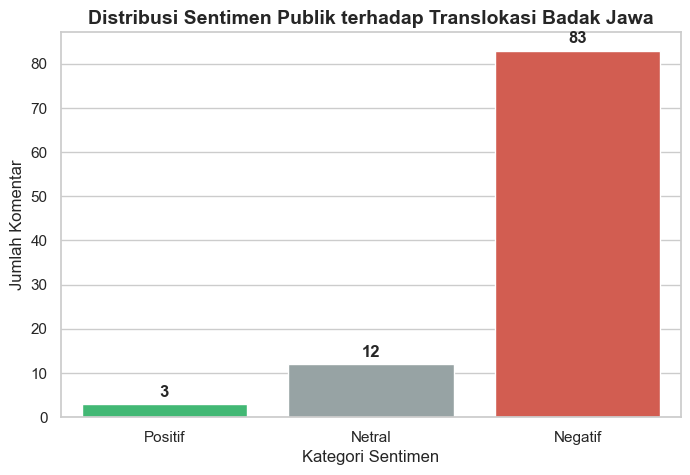

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_csv('hasil_anotasi_badak_jawa.csv', encoding='utf-8-sig')

# Mengatur gaya grafik
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

# Menghitung jumlah sentimen dan mengurutkannya
urutan_sentimen = ['Positif', 'Netral', 'Negatif']
jumlah = df['sentimen'].value_counts().reindex(urutan_sentimen)

# Membuat grafik batang
warna = ['#2ecc71', '#95a5a6', '#e74c3c'] # Hijau, Abu-abu, Merah
ax = sns.barplot(x=jumlah.index, y=jumlah.values, palette=warna)

# Menambahkan angka jumlah di atas masing-masing batang
for i, v in enumerate(jumlah.values):
    ax.text(i, v + 1, str(v), ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.title('Distribusi Sentimen Publik terhadap Translokasi Badak Jawa', fontsize=14, fontweight='bold')
plt.xlabel('Kategori Sentimen')
plt.ylabel('Jumlah Komentar')
plt.show()

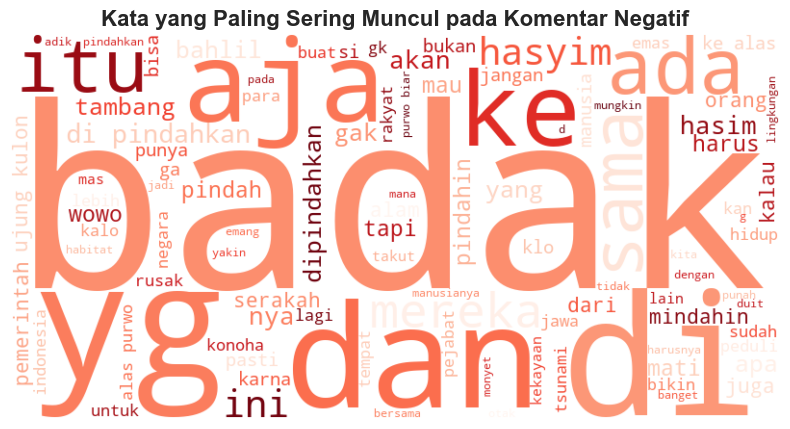

In [2]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Menggabungkan semua teks komentar negatif
teks_negatif = " ".join(df[df['sentimen'] == 'Negatif']['teks_komentar'].astype(str))

# Membuat Word Cloud
wordcloud = WordCloud(width=800, height=400, background_color='white', 
                      colormap='Reds', max_words=100).generate(teks_negatif)

# Menampilkan
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Kata yang Paling Sering Muncul pada Komentar Negatif', fontsize=16, fontweight='bold')
plt.show()

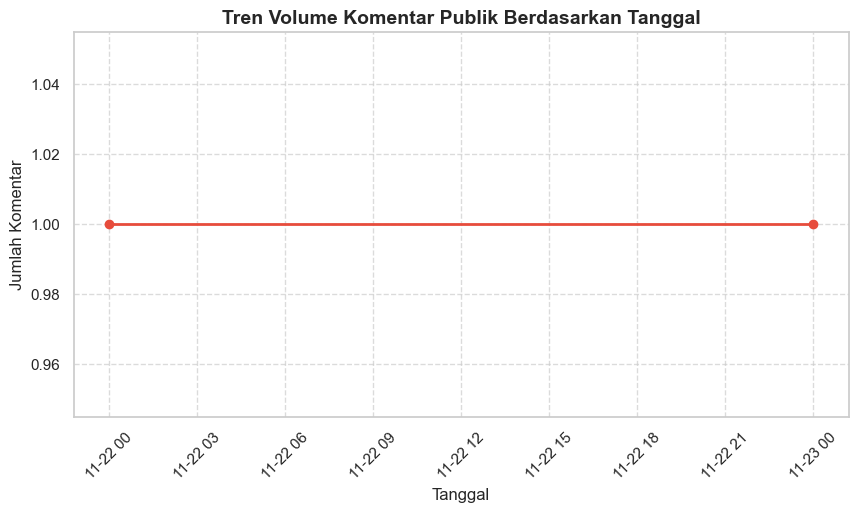

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load file mentah (yang punya kolom tanggal)
df_raw = pd.read_csv('dataset_badak_jawa.csv')
# 2. Load file hasil anotasi (yang punya label sentimen)
df_anotasi = pd.read_csv('hasil_anotasi_badak_jawa.csv', encoding='utf-8-sig')

# 3. Gabungkan kedua data berdasarkan isi teks komentarnya
df_merged = pd.merge(df_raw, df_anotasi, left_on='komentar', right_on='teks_komentar', how='inner')

# 4. Proses tanggal
df_merged['tanggal'] = pd.to_datetime(df_merged['tanggal'])
df_merged['tanggal_hari'] = df_merged['tanggal'].dt.date
tren_harian = df_merged['tanggal_hari'].value_counts().sort_index()

# 5. Membuat grafik
plt.figure(figsize=(10, 5))
plt.plot(tren_harian.index, tren_harian.values, marker='o', color='#e74c3c', linewidth=2)
plt.title('Tren Volume Komentar Publik Berdasarkan Tanggal', fontsize=14, fontweight='bold')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Komentar')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

/var/folders/hk/75d52h756x149znkfs91shg00000gp/T/ipykernel_10194/150599216.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(top_10_kata.values()), y=list(top_10_kata.keys()), palette='Reds_r')


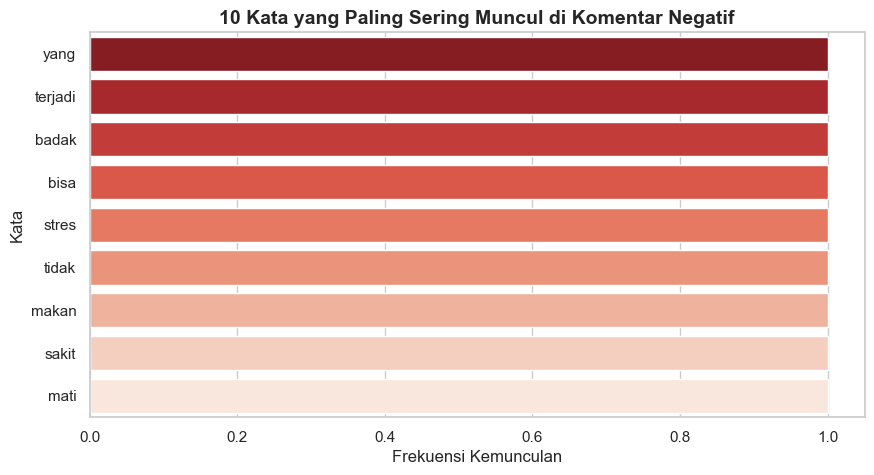

In [4]:
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

# Mengambil kata dari data yang sudah digabung
semua_kata = " ".join(df_merged[df_merged['sentimen'] == 'Negatif']['teks_komentar'].astype(str)).split()
# Menghitung frekuensi (abaikan kata < 3 huruf seperti 'yg', 'di', 'ke')
frekuensi_kata = Counter([kata for kata in semua_kata if len(kata) > 3])
top_10_kata = dict(frekuensi_kata.most_common(10))

# Membuat grafik
plt.figure(figsize=(10, 5))
sns.barplot(x=list(top_10_kata.values()), y=list(top_10_kata.keys()), palette='Reds_r')
plt.title('10 Kata yang Paling Sering Muncul di Komentar Negatif', fontsize=14, fontweight='bold')
plt.xlabel('Frekuensi Kemunculan')
plt.ylabel('Kata')
plt.show()

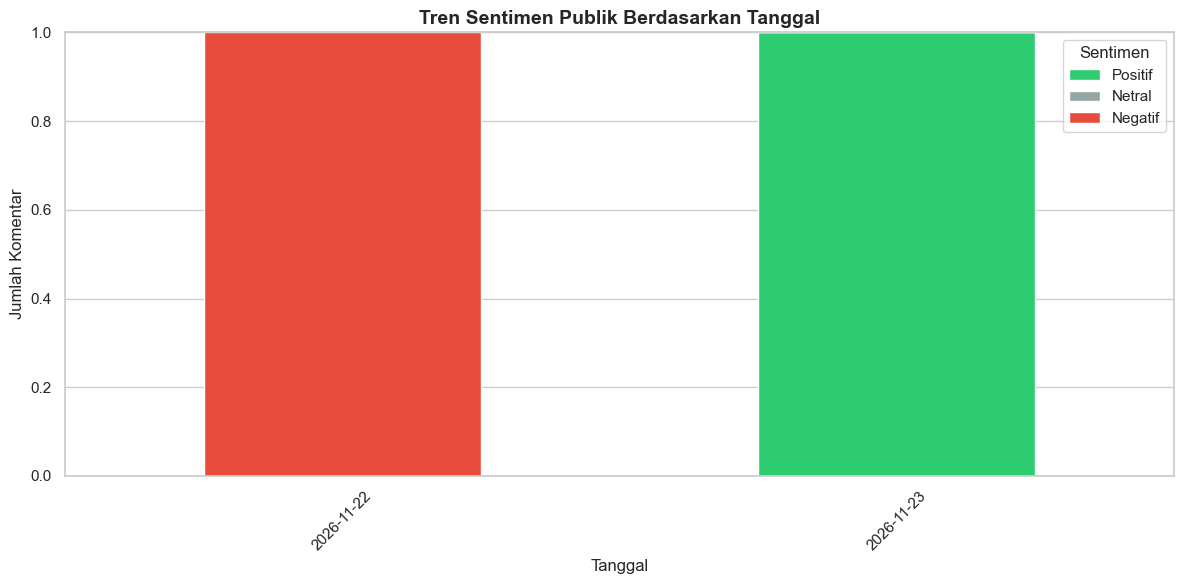

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Pastikan df_merged sudah ada di memori (dari sel sebelumnya)

# 1. Membuat tabel silang antara tanggal dan sentimen
tren_sentimen = pd.crosstab(df_merged['tanggal_hari'], df_merged['sentimen'])

# 2. KUNCI PERBAIKAN: Paksa semua kolom untuk selalu ada. 
# Jika tidak ada data, isi dengan 0 (fill_value=0)
tren_sentimen = tren_sentimen.reindex(columns=['Positif', 'Netral', 'Negatif'], fill_value=0)

# 3. Membuat grafik batang bertumpuk
ax = tren_sentimen.plot(kind='bar', stacked=True, figsize=(12, 6), 
                        color=['#2ecc71', '#95a5a6', '#e74c3c'])

plt.title('Tren Sentimen Publik Berdasarkan Tanggal', fontsize=14, fontweight='bold')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Komentar')
plt.xticks(rotation=45)
plt.legend(title='Sentimen', loc='upper right')
plt.tight_layout()
plt.show()

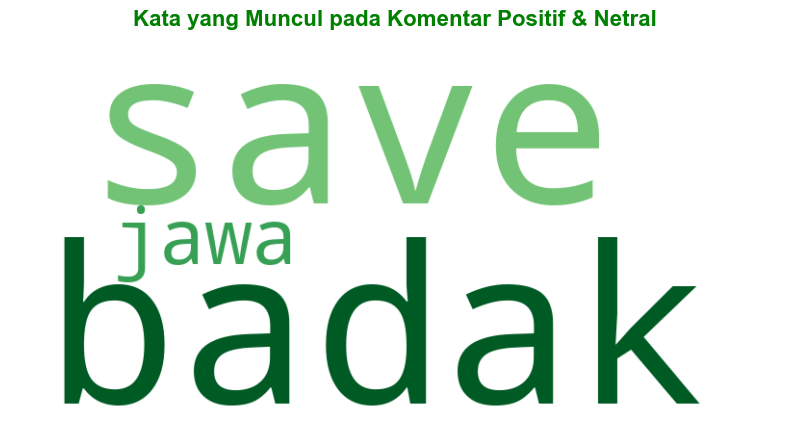

In [6]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Menggabungkan teks Positif dan Netral
teks_positif_netral = " ".join(df_merged[df_merged['sentimen'].isin(['Positif', 'Netral'])]['teks_komentar'].astype(str))

# Membuat Word Cloud
wordcloud_pos = WordCloud(width=800, height=400, background_color='white', 
                          colormap='Greens', max_words=100).generate(teks_positif_netral)

# Menampilkan
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_pos, interpolation='bilinear')
plt.axis('off')
plt.title('Kata yang Muncul pada Komentar Positif & Netral', fontsize=16, fontweight='bold', color='green')
plt.show()

/var/folders/hk/75d52h756x149znkfs91shg00000gp/T/ipykernel_10194/2776876879.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frekuensi', y='Frasa', data=df_bigram, palette='Oranges_r')


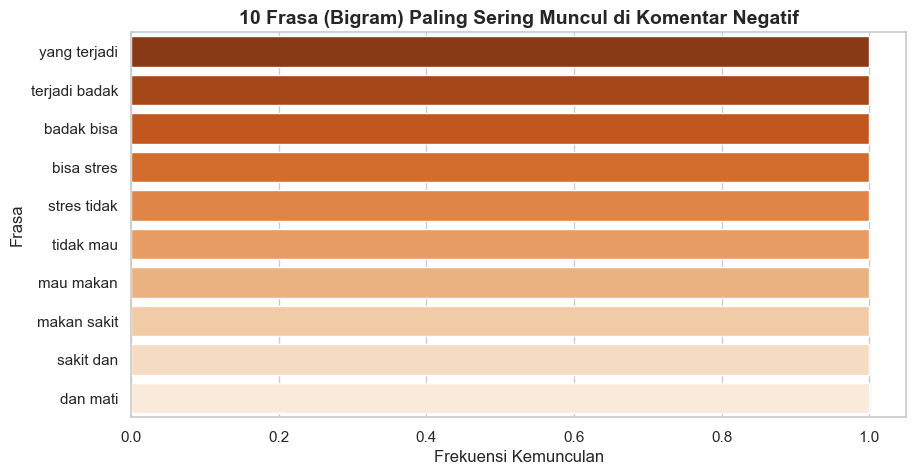

In [7]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Mengambil teks
teks_negatif = df_merged[df_merged['sentimen'] == 'Negatif']['teks_komentar'].astype(str)

# Mencari pasangan 2 kata (bigram)
vec = CountVectorizer(ngram_range=(2, 2), stop_words='english').fit(teks_negatif)
bag_of_words = vec.transform(teks_negatif)
sum_words = bag_of_words.sum(axis=0) 
words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
words_freq = sorted(words_freq, key = lambda x: x[1], reverse=True)[:10]

# Mengubah ke DataFrame
df_bigram = pd.DataFrame(words_freq, columns=['Frasa', 'Frekuensi'])

# Membuat grafik
plt.figure(figsize=(10, 5))
sns.barplot(x='Frekuensi', y='Frasa', data=df_bigram, palette='Oranges_r')
plt.title('10 Frasa (Bigram) Paling Sering Muncul di Komentar Negatif', fontsize=14, fontweight='bold')
plt.xlabel('Frekuensi Kemunculan')
plt.ylabel('Frasa')
plt.show()